# Parsing comparison: how should the model read a page?

When an LLM gets something wrong, the cause is often bad context, so the first question is how to turn a PDF page
into model input. This notebook compares four ways on the case pages (mainly p.51 and p.71):

1. **Text layer** (`page.get_text("text")`): cheapest. Also used for search and token counts.
2. **Font-aware text**: the text layer with font sizes turned into markdown headings.
3. **Vision OCR**: render the page to PNG and let Luna transcribe it to markdown.
4. **Risks straight from the image**: Luna gets the page image and returns risks directly, no text step.

The conclusion is at the bottom. Page numbers are 1-indexed PDF pages (same as the case brief).
Sections 3 and 4 call Azure OpenAI (needs `.env` and the VPN).

In [1]:
# Re-import edited modules (e.g. annual_report_reader) automatically before each cell runs
%load_ext autoreload
%autoreload 2

In [2]:
import html
import re

import pandas as pd
import pymupdf
import tiktoken
from dotenv import load_dotenv
from IPython.display import HTML, Image, Markdown, display
from langchain_core.messages import HumanMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

from annual_report_reader.chat import Usage, azure_chat_model
from annual_report_reader.extraction.chain import extraction_chain
from annual_report_reader.extraction.config import REPO_ROOT, ExtractionConfig
from annual_report_reader.extraction.pages import PageGroup, render_pages
from annual_report_reader.extraction.prompts import load_prompt
from annual_report_reader.extraction.schema import ExtractedRisks

load_dotenv(REPO_ROOT / ".env")

PDF_PATH = REPO_ROOT / "data/VestasAnnualReport2025.pdf"
doc = pymupdf.open(PDF_PATH)

# Read all text once: {page_number (1-indexed): text}
pages = {i + 1: page.get_text("text") for i, page in enumerate(doc)}
print(f"Loaded {len(pages)} pages from {PDF_PATH.name}")

# Today's step-1 settings (deployment, effort, prompt, prices): sections 3-4 run on the same stack as notebook 01.
CONFIG = ExtractionConfig()

Loaded 195 pages from VestasAnnualReport2025.pdf


## Helpers: search and render pages

In [3]:
def _norm(s: str) -> str:
    """Join line breaks / hyphenated breaks so phrases split across lines still match."""
    s = s.replace("\ufffd", "")  # unrenderable glyphs (e.g. ToC dot leaders)
    s = re.sub(r"(?<=\w)-\n(?=\w)", "", s)
    return re.sub(r"\s+", " ", s)


def search(query: str, *, regex: bool = False, case: bool = False, context: int = 80) -> dict[int, list[str]]:
    """Return {page_number: [snippet, ...]} for every page containing `query`.

    - regex: treat `query` as a regular expression
    - case:  case-sensitive match
    - context: characters of context on each side of the snippet
    """
    flags = 0 if case else re.IGNORECASE
    pattern = re.compile(query if regex else re.escape(query), flags)
    hits: dict[int, list[str]] = {}
    for pno, text in pages.items():
        t = _norm(text)
        for m in pattern.finditer(t):
            a, b = max(0, m.start() - context), min(len(t), m.end() + context)
            snippet = (
                ("…" if a else "")
                + t[a : m.start()]
                + "**"
                + m.group()
                + "**"
                + t[m.end() : b]
                + ("…" if b < len(t) else "")
            )
            hits.setdefault(pno, []).append(snippet)
    return hits


def show_hits(hits: dict[int, list[str]], max_per_page: int = 5) -> None:
    total = sum(len(v) for v in hits.values())
    lines = [f"**{total} matches on {len(hits)} pages:** {sorted(hits)}", ""]
    for pno, snippets in sorted(hits.items()):
        lines.append(f"### Page {pno} ({len(snippets)})")
        lines += [f"- {s}" for s in snippets[:max_per_page]]
        if len(snippets) > max_per_page:
            lines.append(f"- … {len(snippets) - max_per_page} more")
    display(Markdown("\n".join(lines)))


def show_page(page_number: int, query: str | None = None, *, zoom: float = 1.5, color=(1, 1, 0)) -> None:
    """Render a page as an image, highlighting every occurrence of `query` (plain text, case-insensitive)."""
    src = pymupdf.open(PDF_PATH)  # fresh copy so highlights don't accumulate on `doc`
    page = src[page_number - 1]
    n = 0
    if query:
        quads = page.search_for(query, quads=True)
        n = len(quads)
        if quads:
            annot = page.add_highlight_annot(quads)
            annot.set_colors(stroke=color)
            annot.update()
    pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), annots=True)
    display(Markdown(f"**Page {page_number}**" + (f" — {n} highlight(s) for `{query}`" if query else "")))
    display(Image(data=pix.tobytes("png")))
    src.close()


def show_pages(query: str, page_numbers=None, **kw) -> None:
    """Render each page where `query` occurs (or the given pages) with highlights."""
    if page_numbers is None:
        page_numbers = sorted(search(query))
    for pno in page_numbers:
        show_page(pno, query, **kw)

## 1. Text layer: size and cost of the whole report

What would it cost to send the whole report as plain text? Token counts use `o200k_base` (the GPT-4o / GPT-5
encoding), and the pricing is Luna's.

In [4]:
all_text = " ".join(pages.values())

# Luna = Azure deployment of gpt-5.6. tiktoken may not know that model name yet, so fall back to
# o200k_base (the GPT-4o / GPT-5 family encoding). Verify against `usage.prompt_tokens` from a real call.
try:
    enc = tiktoken.encoding_for_model("gpt-5.6")
except KeyError:
    enc = tiktoken.get_encoding("o200k_base")

n_tokens = len(enc.encode(all_text))
per_page = {p: len(enc.encode(t)) for p, t in pages.items()}
print(f"Encoding: {enc.name}")
print(f"Total: {n_tokens:,} tokens, {len(all_text):,} chars ({len(all_text) / n_tokens:.1f} chars/token)")
print(
    f"Per page: avg {n_tokens / len(pages):,.0f}, max {max(per_page.values()):,} (page {max(per_page, key=per_page.get)})"
)

Encoding: o200k_base
Total: 173,472 tokens, 752,328 chars (4.3 chars/token)
Per page: avg 890, max 2,162 (page 91)


In [5]:
# Luna pricing (USD per 1M tokens), as in the extraction config
PRICE_IN_PER_M = CONFIG.price_in_per_m
PRICE_OUT_PER_M = CONFIG.price_out_per_m

# Output size is a guess: set it to what you expect the model to return
# (or use `usage.completion_tokens` from a real run). Reasoning tokens are billed as output.
OUTPUT_TOKENS = 20_000


def cost(input_tokens: int, output_tokens: int) -> tuple[float, float, float]:
    cin = input_tokens / 1e6 * PRICE_IN_PER_M
    cout = output_tokens / 1e6 * PRICE_OUT_PER_M
    return cin, cout, cin + cout


cin, cout, total = cost(n_tokens, OUTPUT_TOKENS)
print(f"Input : {n_tokens:>9,} tokens  ${cin:.4f}")
print(f"Output: {OUTPUT_TOKENS:>9,} tokens  ${cout:.4f}")
print(f"Total :                   ${total:.4f}")

Input :   173,472 tokens  $0.0347
Output:    20,000 tokens  $0.0240
Total :                   $0.0587


Search example: every match of "cyber" on p.51, highlighted.

**Page 51** — 13 highlight(s) for `cyber`

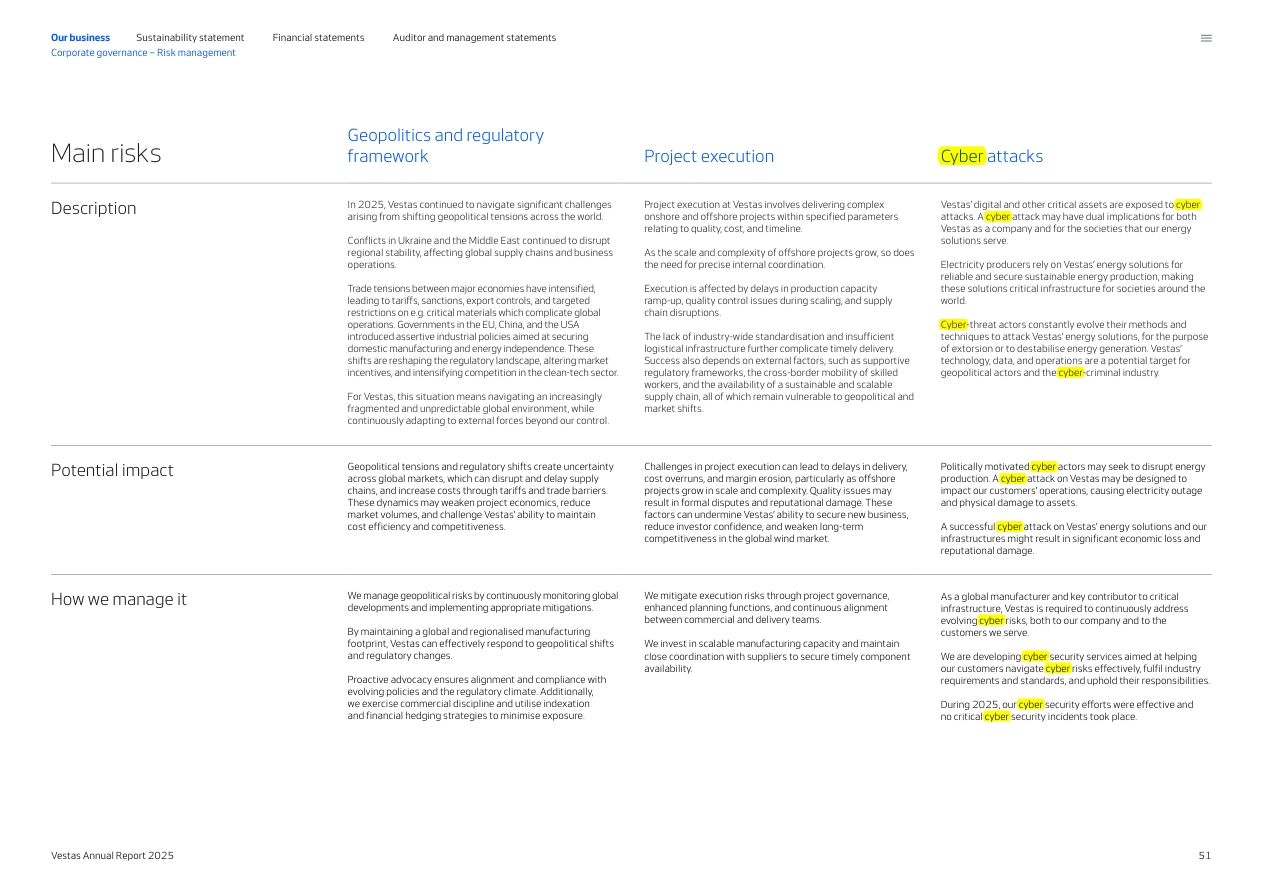

In [6]:
show_page(51, "cyber")

## 2. Font-aware text (markdown headings from font size)

`get_text("text")` drops all font information. Here we read spans with `get_text("dict")` and turn
font size into markdown headings (body text is 7-8pt in this report):

| size | becomes |
|---|---|
| ≥ 24pt | `# heading` |
| ≥ 14pt | `## heading` |
| ≥ 11pt | `### heading` (e.g. risk names on p.51) |
| body, all bold | `**text**` |

Lines without letters (big KPI numbers) stay plain. A wrapped heading is merged only with the line above it
if both start at the same x (same column), so side-by-side column headers stay separate.

Note: `pymupdf4llm.to_markdown` was tried first. Its layout mode reads p.51 row-wise across the three
risk columns (mixing sentences), and its legacy mode keeps the order but marks no headings.

In [7]:
CTRL_RE = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f�]")  # control chars / unrenderable glyphs


def heading_level(size: float) -> int:
    return 1 if size >= 24 else 2 if size >= 14 else 3 if size >= 11 else 0


def is_bold(span: dict) -> bool:
    return bool(span["flags"] & 16) or any(w in span["font"] for w in ("Bold", "Semibold", "Black"))


def md_page(page: pymupdf.Page) -> str:
    """Page text in PyMuPDF's plain reading order, with font size turned into markdown headings."""
    out: list[str] = []
    for block in page.get_text("dict")["blocks"]:
        if block["type"] != 0:  # image block
            continue
        prev_lvl, prev_x = 0, None
        for line in block["lines"]:
            spans = [s for s in line["spans"] if s["text"].strip()]
            text = CTRL_RE.sub("", "".join(s["text"] for s in line["spans"])).strip()
            if not spans or not text:
                continue
            lvl = heading_level(max(s["size"] for s in spans)) if re.search(r"[A-Za-z]", text) else 0
            x0 = line["bbox"][0]
            if lvl and lvl == prev_lvl and abs(x0 - prev_x) < 2:
                out[-1] += " " + text  # heading wrapped onto the next line, same column
            elif lvl:
                out.append("#" * lvl + " " + text)
            elif all(is_bold(s) for s in spans):
                out.append(f"**{text}**")
            else:
                out.append(text)
            prev_lvl, prev_x = lvl, x0
        out.append("")
    return re.sub(r"\n{3,}", "\n\n", "\n".join(out)).strip()


md_pages = {i + 1: md_page(page) for i, page in enumerate(doc)}
plain_tok = sum(len(enc.encode(t)) for t in pages.values())
md_tok = sum(len(enc.encode(t)) for t in md_pages.values())
print(f"plain: {plain_tok:,} tokens | markdown: {md_tok:,} tokens ({md_tok / plain_tok - 1:+.1%})")

plain: 173,413 tokens | markdown: 169,025 tokens (-2.5%)


In [8]:
def compare_text(page_number: int, n_chars: int = 2500) -> None:
    """Plain text vs font-aware markdown for one page, side by side."""
    col = "<div style='flex:1;min-width:0'><b>{}</b><pre style='white-space:pre-wrap;font-size:11px'>{}</pre></div>"
    left = col.format("plain", html.escape(pages[page_number][:n_chars]))
    right = col.format("markdown", html.escape(md_pages[page_number][:n_chars]))
    display(HTML(f"<h4>Page {page_number}</h4><div style='display:flex;gap:16px'>{left}{right}</div>"))


for pno in (50, 51):
    compare_text(pno)

## 3. Vision OCR: Luna transcribes the page image

Render the page to PNG (200 DPI) and ask Luna for a verbatim markdown transcription. Compare the result with the
two text-layer versions, side by side.

In [9]:
OCR_PROMPT = """Transcribe this annual-report page to markdown, verbatim. Do not summarise, translate or add anything.
- Use #/##/### for headings according to their visual size.
- Skip the running header/footer navigation and the page number.
- The page may be laid out as a grid/table (column headers across the top, row labels down the left).
  Preserve that structure so every text cell stays with its row and column header: output one section
  per column heading, and inside it one subsection per row label, in the order they appear.
- Keep paragraph breaks. Join words hyphenated across line breaks."""


ocr_model = azure_chat_model(CONFIG.deployment, None)  # transcription: the deployment's default effort


def ocr_page(page_number: int, dpi: int = 200, prompt: str = OCR_PROMPT) -> dict:
    """Render the page and ask Luna to transcribe it."""
    (image,) = render_pages(PDF_PATH, [page_number], dpi)
    msg = ocr_model.invoke(
        [
            HumanMessage(
                content=[
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": image.data_url}},
                ]
            )
        ]
    )
    usage = Usage.of(msg)
    return {
        "page": page_number,
        "dpi": dpi,
        "text": msg.content,
        "tokens_in": usage.input_tokens,
        "tokens_out": usage.output_tokens,
    }


OCR_PAGE = 51
ocr = ocr_page(OCR_PAGE)
print(
    f"in {ocr['tokens_in']:,} / out {ocr['tokens_out']:,} tokens | ${cost(ocr['tokens_in'], ocr['tokens_out'])[2]:.4f}"
)

in 3,372 / out 1,121 tokens | $0.0020


**Page 51**

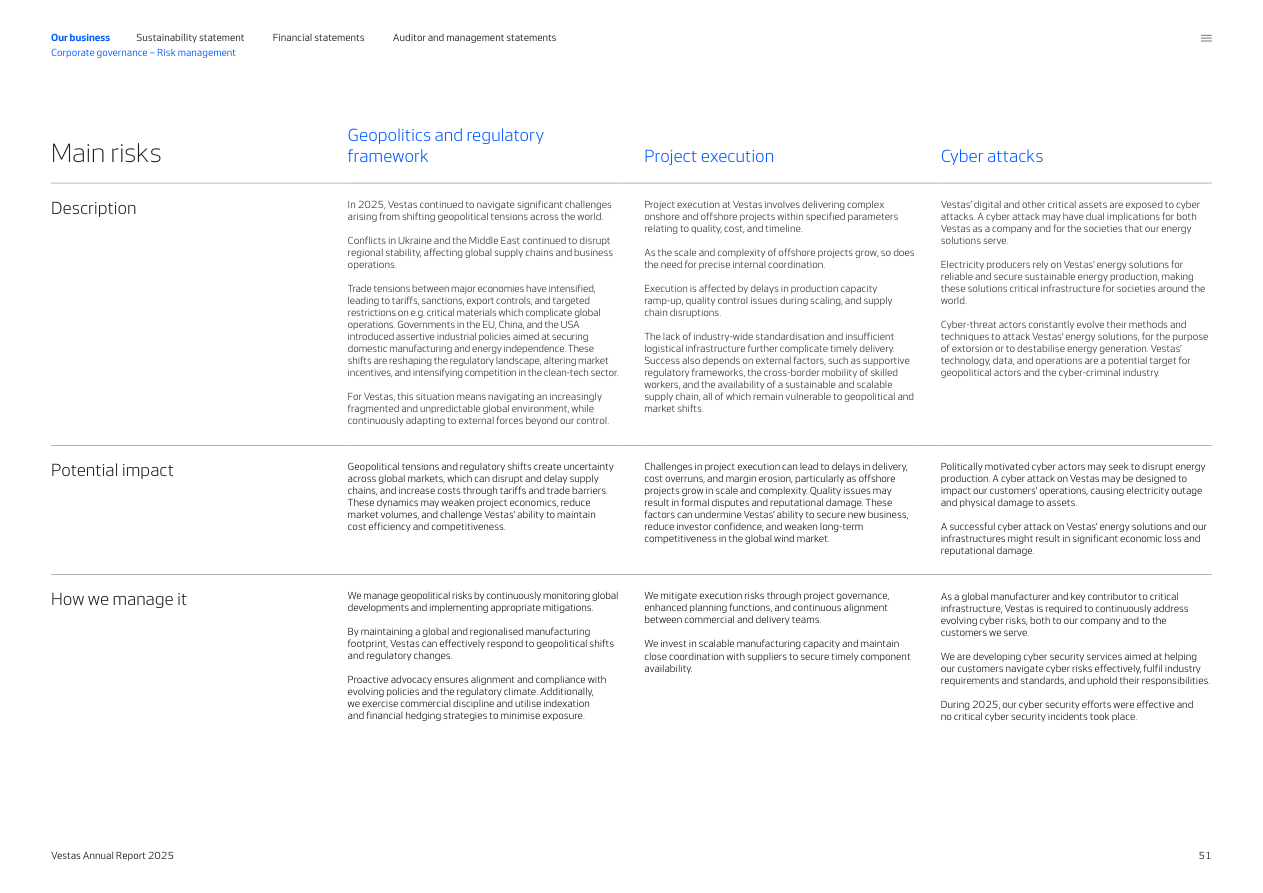

In [10]:
# Compare: plain text | font-aware markdown | Luna OCR (full page, scroll each column). Page image below.
def compare3(page_number: int, ocr_text: str) -> None:
    col = (
        "<div style='flex:1;min-width:0'><b>{}</b><pre style='white-space:pre-wrap;font-size:11px;"
        "max-height:900px;overflow:auto'>{}</pre></div>"
    )
    cols = [
        ("plain (get_text)", pages[page_number]),
        ("markdown (md_page)", md_pages[page_number]),
        ("Luna OCR", ocr_text),
    ]
    body = "".join(col.format(t, html.escape(s)) for t, s in cols)
    display(HTML(f"<h4>Page {page_number}</h4><div style='display:flex;gap:12px'>{body}</div>"))


compare3(OCR_PAGE, ocr["text"])
show_page(OCR_PAGE)

in 3,372 / out 1,499 tokens | $0.0025


**Page 71**

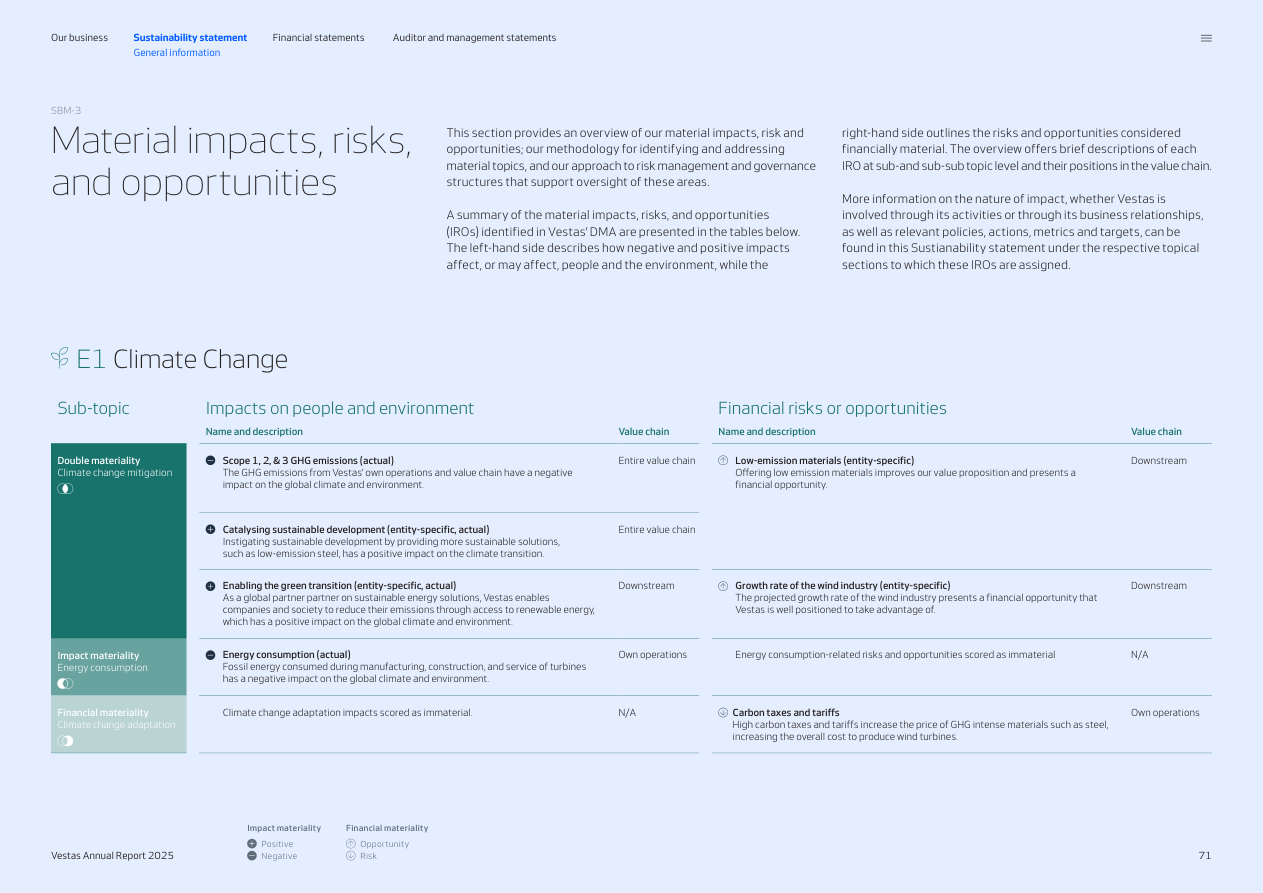

In [11]:
# Same comparison for p.71 (a MUST page: the ESRS table of impacts, risks and opportunities)
ocr71 = ocr_page(71)
print(
    f"in {ocr71['tokens_in']:,} / out {ocr71['tokens_out']:,} tokens "
    f"| ${cost(ocr71['tokens_in'], ocr71['tokens_out'])[2]:.4f}"
)
compare3(71, ocr71["text"])
show_page(71)

## 4. Risks straight from the image (no text step)

OCR first transcribes and then extracts, and the transcription loses layout: which cell belongs to which
row and column, and the impact/risk/opportunity markers. Here Luna gets the **page image** and returns risks
directly, through the same chain as notebook 01 (`extraction.chain`, prompt `CONFIG.prompt`, schema
`ExtractedRisks`).

For comparison, the same prompt also runs on the page's **plain text**. Only the two sentences that say the page
is an image are reworded, so the input is the only thing that changes.

In [12]:
definition = CONFIG.resolve(CONFIG.definition_path).read_text(encoding="utf-8")
prompt_dir = CONFIG.resolve(CONFIG.prompt_dir)
model = azure_chat_model(CONFIG.deployment, CONFIG.reasoning_effort)

# Image: exactly notebook 01's chain.
image_prompt = load_prompt(prompt_dir, CONFIG.prompt, definition)
image_chain = extraction_chain(image_prompt, model)

# Text: the same system prompt with the image wording swapped, and the page's text layer as the user message.
TEXT_SWAPS = {
    "Each page is given as an image,": "Each page is given as its extracted text,",
    "as given before its image.": "as given before its text.",
}
text_system = (prompt_dir / f"{CONFIG.prompt}.md").read_text(encoding="utf-8").removesuffix("\n")
for old, new in TEXT_SWAPS.items():
    assert old in text_system, f"swap failed: {old!r} is not in {CONFIG.prompt}"
    text_system = text_system.replace(old, new)
text_prompt = ChatPromptTemplate.from_messages([("system", text_system), MessagesPlaceholder("pages")]).partial(
    PRINCIPAL_RISK_DEFINITION=definition.removesuffix("\n")
)
structured = model.with_structured_output(ExtractedRisks, method="json_schema", strict=True, include_raw=True)
text_chain = text_prompt | structured


def image_risks(page_number: int) -> dict:
    return image_chain.invoke(PageGroup(tuple(render_pages(PDF_PATH, [page_number], CONFIG.dpi))))


def text_risks(page_number: int) -> dict:
    return text_chain.invoke({"pages": [HumanMessage(f"Page {page_number}\n\n{pages[page_number].strip()}")]})


results_71 = {"image": image_risks(71), "text": text_risks(71)}
for name, out in results_71.items():
    if out["parsed"] is None:
        raise ValueError(f"{name}: no parsed output ({out['parsing_error']!r})")
    u = Usage.of(out["raw"])
    print(
        f"{name:5} | {len(out['parsed'].risks)} risks "
        f"| in {u.input_tokens:,} / out {u.output_tokens:,} | ${cost(u.input_tokens, u.output_tokens)[2]:.4f}"
    )

image | 1 risks | in 4,427 / out 302 | $0.0012
text  | 1 risks | in 1,844 / out 229 | $0.0006


The system prompt the image call gets (the text call differs only in the swapped sentences):

In [13]:
print(image_prompt.format_messages(pages=[])[0].content)

You extract principal risks from consecutive pages of a company annual report. Each page is given as an image,
preceded by its page number (e.g. "Page 71"). Read the pages together: a table, a list or a risk description can
continue from one page onto the next, and a legend or heading on one page can explain items on another.

## Definition of a principal risk

A principal risk is an uncertain event or condition that the reporting company
itself presents as having the potential to materially affect its strategy,
financial performance, operations, reputation, or viability, and as significant
enough to warrant board- or executive-level attention.

A principal risk has these characteristics:
- **It is a risk to the company.** It describes how external or internal
  factors could affect the company (outside-in), not how the company affects
  people or the environment (inside-out).
- **It has downside potential.** Opportunities, even uncertain ones, are not
  risks.
- **It is material.** Th

In [14]:
# The LLM output per input (image vs text): every risk with all its fields


def risks_df(results: dict) -> pd.DataFrame:
    rows = [
        {"source": source, **risk.model_dump(mode="json")}
        for source, out in results.items()
        for risk in out["parsed"].risks
    ]
    return pd.DataFrame(rows)


def show_risks(df: pd.DataFrame) -> None:
    """Full-width HTML table; list cells one item per line."""
    fmt = lambda v: "<br>".join(html.escape(str(x)) for x in v) if isinstance(v, list) else html.escape(str(v))
    table = df.map(fmt).to_html(escape=False, index=False)
    display(HTML(f"<div style='font-size:12px;text-align:left'>{table}</div>"))


show_risks(risks_df(results_71))

source,page,title,category,secondary_category,section,description,mitigation,confidence
image,71,Carbon taxes and tariffs,climate,financial,E1 Climate Change - Financial risks or opportunities,"High carbon taxes and tariffs increase the price of GHG intense materials such as steel, increasing the overall cost to produce wind turbines.",None,high
text,71,Carbon taxes and tariffs,regulatory,financial,E1 Climate Change - Financial risks or opportunities,"High carbon taxes and tariffs increase the price of GHG intense materials such as steel, increasing the overall cost to produce wind turbines.",None,high


## 5. Conclusion

| Approach | What happened | Verdict |
|---|---|---|
| 1. Text layer | Cheap (~890 tokens per page, ~$0.06 for the whole report), but it does not keep the reading order on graphical pages: on grid and column layouts, text cells lose their row and column header. | Not reliable enough as model input |
| 2. Font-aware text | Adds headings at no extra cost (-2.5% tokens), but keeps the text layer's reading order. `pymupdf4llm` was worse: it read p.51 row-wise across the three risk columns. | Same problem as 1 |
| 3. Vision OCR | Gets the reading order right, but the transcription loses layout: which cell belongs to which row and column, and the impact / risk / opportunity markers. Those cues decide whether an entry is a principal risk. | Information loss |
| 4. Image → risks | One call, and the model sees the layout and markers the way a person does. Costs about 2.4x the input tokens of the text version on p.71 (4,430 vs 1,843), which is still around $0.001 per page. Re-run with today's step-1 prompt (`extract`): on p.71 both inputs find the one golden risk, and the text version gets its category wrong (`regulatory` vs `climate`). | **Chosen for the pipeline** (see `DESIGN.md`) |

Not tried: document layout extraction (models that combine the image and the text layer). It is more complex,
and I did not think it was worth it within the time budget.